In [1]:
import numpy as np
from helpers import *
from implementations import *
import csv
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [2]:
x_train, x_test, y_train, train_ids, test_ids= load_csv_data("dataset/") ####DO NOT RERUNNNNNNNNNN!!!!!!

## PART 1 VIS AND DATASET ANALYSIS

In [3]:
with open("dataset/x_train.csv") as f:
    feature_names = next(csv.reader(f))[1:]
feature_names

['_STATE',
 'FMONTH',
 'IDATE',
 'IMONTH',
 'IDAY',
 'IYEAR',
 'DISPCODE',
 'SEQNO',
 '_PSU',
 'CTELENUM',
 'PVTRESD1',
 'COLGHOUS',
 'STATERES',
 'CELLFON3',
 'LADULT',
 'NUMADULT',
 'NUMMEN',
 'NUMWOMEN',
 'CTELNUM1',
 'CELLFON2',
 'CADULT',
 'PVTRESD2',
 'CCLGHOUS',
 'CSTATE',
 'LANDLINE',
 'HHADULT',
 'GENHLTH',
 'PHYSHLTH',
 'MENTHLTH',
 'POORHLTH',
 'HLTHPLN1',
 'PERSDOC2',
 'MEDCOST',
 'CHECKUP1',
 'BPHIGH4',
 'BPMEDS',
 'BLOODCHO',
 'CHOLCHK',
 'TOLDHI2',
 'CVDSTRK3',
 'ASTHMA3',
 'ASTHNOW',
 'CHCSCNCR',
 'CHCOCNCR',
 'CHCCOPD1',
 'HAVARTH3',
 'ADDEPEV2',
 'CHCKIDNY',
 'DIABETE3',
 'DIABAGE2',
 'SEX',
 'MARITAL',
 'EDUCA',
 'RENTHOM1',
 'NUMHHOL2',
 'NUMPHON2',
 'CPDEMO1',
 'VETERAN3',
 'EMPLOY1',
 'CHILDREN',
 'INCOME2',
 'INTERNET',
 'WEIGHT2',
 'HEIGHT3',
 'PREGNANT',
 'QLACTLM2',
 'USEEQUIP',
 'BLIND',
 'DECIDE',
 'DIFFWALK',
 'DIFFDRES',
 'DIFFALON',
 'SMOKE100',
 'SMOKDAY2',
 'STOPSMK2',
 'LASTSMK2',
 'USENOW3',
 'ALCDAY5',
 'AVEDRNK2',
 'DRNK3GE5',
 'MAXDRNKS',
 'FRUITJU

In [4]:
len(feature_names)

321

after the tedious work of reading the documentation in order to assert what features are nominal/categorical we have:

In [5]:
categorical = [
    "HLTHPLN1", "MEDCOST", "BPMEDS", "BLOODCHO", "TOLDHI2", "CVDSTRK3",
    "ASTHMA3", "ASTHNOW", "CHCSCNCR", "CHCOCNCR", "CHCCOPD1", "HAVARTH3",
    "ADDEPEV2", "CHCKIDNY", "SEX", "NUMHHOL2", "CPDEMO1", "VETERAN3",
    "INTERNET", "PREGNANT", "QLACTLM2", "USEEQUIP", "BLIND", "DECIDE",
    "DIFFWALK", "DIFFDRES", "DIFFALON", "SMOKE100", "STOPSMK2", "EXERANY2",
    "LMTJOIN3", "ARTHDIS2", "FLUSHOT6", "PNEUVAC3", "HIVTST6", "PDIABTST",
    "INSULIN", "DIABEYE", "DIABEDU", "CRGVPERS", "CRGVHOUS", "CRGVEXPT",
    "VIGLUMA2", "VIMACDG2", "CIMEMLOS", "CDDISCUS", "WTCHSALT", "DRADVISE",
    "ASATTACK", "HAREHAB1", "STREHAB1", "CVDASPRN", "RLIVPAIN", "RDUCHART",
    "RDUCSTRK", "ARTHWGT", "ARTHEXER", "ARTHEDU", "SHINGLE2", "HADMAM",
    "HADPAP2", "HPVTEST", "HADHYST2", "PROFEXAM", "BLDSTOOL", "HADSIGM3",
    "HADSGCO1", "PCPSAAD2", "PCPSADI1", "PCPSARE1", "PSATEST1", "RCSGENDR",
    "CASTHDX2", "CASTHNO2", "MISTMNT", "ADANXEV", "_CHISPNC", "_RFHLTH",
    "_HCVU651", "_RFHYPE5", "_RFCHOL", "_LTASTH1", "_CASTHM1", "_DRDXAR1",
    "_HISPANC", "_RACEG21", "_AGE65YR", "_RFBMI5", "_RFSMOK3", "DRNKANY5",
    "_RFBING5", "_RFDRHV5", "_FRTRESP", "_VEGRESP", "_FRTLT1", "_VEGLT1",
    "_FRT16", "_VEG23", "_TOTINDA", "PAMISS1_", "_PAINDX1", "_PA30021",
    "_PASTRNG", "_PASTAE1", "_RFSEAT2", "_RFSEAT3", "_FLSHOT6", "_PNEUMO2",
    "_AIDTST3","_STATE", "PERSDOC2", "BPHIGH4", "DIABETE3", "MARITAL", "RENTHOM1",
    "EMPLOY1", "EXRACT11", "EXRACT21", "IMFVPLAC", "WHRTST10", "PREDIAB1",
    "CAREGIV1", "CRGVREL1", "CRGVPRB1", "CRGVMST2", "VIDFCLT2", "VIREDIF3",
    "VINOCRE2", "VIEYEXM2", "VIINSUR2", "VICTRCT4", "ASPUNSAF", "TETANUS",
    "HPVADVC2", "PCPSARS1", "PCPSADE1", "SCNTPAID", "SCNTLPAD", "SXORIENT",
    "TRNSGNDR", "RCSRLTN2", "QSTLANG", "MSCODE", "_CRACE1", "_CPRACE",
    "_ASTHMS1", "_PRACE1", "_MRACE1", "_RACE", "_RACEGR3", "_RACE_G1",
    "_SMOKER3", "_FRUITEX", "_VEGETEX", "_PAREC1", "_LMTACT1", "_LMTWRK1",
    "_LMTSCL1","GENHLTH", "CHECKUP1", "CHOLCHK", "EDUCA", "INCOME2", "SMOKDAY2",
    "LASTSMK2", "USENOW3", "ARTHSOCL", "SEATBELT", "EYEEXAM", "CRGVLNG1",
    "CRGVHRS1", "VIPRFVS2", "CDHOUSE", "CDASSIST", "CDHELP", "CDSOCIAL",
    "ASYMPTOM", "ASNOSLEP", "ASTHMED3", "ASINHALR", "ARTTODAY", "HPVADSHT",
    "HOWLONG", "LASTPAP2", "HPLSTTST", "LENGEXAM", "LSTBLDS3", "LASTSIG3",
    "PSATIME", "SCNTMNY1", "SCNTMEL1", "EMTSUPRT", "LSATISFY", "_CHOLCHK",
    "_AGEG5YR", "_AGE_G", "_BMI5CAT", "_CHLDCNT", "_EDUCAG", "_INCOMG",
    "ACTIN11_", "ACTIN21_", "_PACAT1", "_PA150R2", "_PA300R2", "DISPCODE", "CTELENUM", "PVTRESD1", "COLGHOUS", "STATERES", "CELLFON3",
    "LADULT", "CTELNUM1", "CELLFON2", "CADULT", "PVTRESD2", "CCLGHOUS",
    "CSTATE", "LANDLINE", "QSTVER", "_STSTR", "_DUALUSE",
]


!!DIABAGE IS A MIX

We can observe that there are tons of categorical variables, as detailled here https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf, we must then use one hot encoding in order to correctly do regression

In [6]:
y = (y_train + 1) / 2

# Train/validation split
indices = np.random.default_rng(42).permutation(len(y))
split = int(0.8 * len(y))
tr, val = indices[:split], indices[split:]

X_tr = pd.DataFrame(x_train[tr], columns=feature_names)
X_val = pd.DataFrame(x_train[val], columns=feature_names)
X_test = pd.DataFrame(x_test, columns=feature_names)

y_tr, y_val = y[tr], y[val]

# One-hot encoding
X_tr = pd.get_dummies(X_tr, columns=categorical, dtype=np.uint8)
X_val = pd.get_dummies(X_val, columns=categorical, dtype=np.uint8)
X_test = pd.get_dummies(X_test, columns=categorical, dtype=np.uint8)

# Align columns with training data
X_val = X_val.reindex(columns=X_tr.columns, fill_value=0)
X_test = X_test.reindex(columns=X_tr.columns, fill_value=0)

# Original non-categorical features
numerical = [c for c in feature_names if c not in categorical]

# Median imputation
medians = X_tr[numerical].median().fillna(0)

for X in (X_tr, X_val, X_test):
    X[numerical] = X[numerical].fillna(medians)

# Standardization
mean = X_tr[numerical].mean()
std = X_tr[numerical].std(ddof=0).replace(0, 1)

for X in (X_tr, X_val, X_test):
    X[numerical] = ((X[numerical] - mean) / std).astype(np.float32)

# Intercept
for X in (X_tr, X_val, X_test):
    X.insert(0, "intercept", 1.0)

/var/folders/8z/7303qst541q9j0wy5w_c5bc00000gn/T/ipykernel_38230/1503710497.py:41: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X.insert(0, "intercept", 1.0)
/var/folders/8z/7303qst541q9j0wy5w_c5bc00000gn/T/ipykernel_38230/1503710497.py:41: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X.insert(0, "intercept", 1.0)
/var/folders/8z/7303qst541q9j0wy5w_c5bc00000gn/T/ipykernel_38230/1503710497.py:41: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor 

In [7]:
##Let's see a bit what distributions in the train and val dataset

totaltrain=len(y_train)
sicktrain=len(y_train[y_train==1])

print(f"Percentage of sick samples in train data : {sicktrain/totaltrain:.2%}")

totalval=len(y_val)
sickval=len(y_val[y_val==1])
print(f"Percentage of sick samples in validation data : {sickval/totalval:.2%}")


Percentage of sick samples in train data : 8.83%
Percentage of sick samples in validation data : 8.88%


The proportion of sick samples is roughly the same in both sets, which is what we want. If the proportions differed too much, we would have used the stratified split method to keep the class distributions similar.

In [8]:
corr = np.corrcoef(X_tr, rowvar=False)

i, j = np.triu_indices_from(corr, k=1)
mask = np.abs(corr[i, j]) > 0.9

strong_pairs = corr[i[mask], j[mask]]

print(f"Found {len(strong_pairs)} highly correlated pairs\n")

Found 317 highly correlated pairs



/opt/anaconda3/lib/python3.12/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/opt/anaconda3/lib/python3.12/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


We can see that there are a lot of features, some of which are strongly correlated. We can therefore try feature selection using L1-regularized logistic regression, which pushes some weights to zero. We then keep only the features with nonzero weights and check whether the model performs better.

In [9]:
def lasso_logistic_regression(y, tx, initial_w, max_iters, gamma,x_val,y_val,_lambda):
    w = initial_w
    losses=[]
    losses_val=[]
    for i in range(max_iters):
        z = tx @ w
        sigma = np.exp(-np.logaddexp(0, -z))
        gradient = tx.T @ (sigma - y) / len(y)
        ##we dont regularize intercept
        gradient[1:]+=_lambda*np.sign(w[1:])
        w = w - gamma * gradient
        if i%10==0:
            z = tx @ w
            loss = np.sum(np.logaddexp(0, z) - y * z) / len(y) +_lambda*np.sum(np.abs(w[1:]))
            losses.append(loss)
            z_val=x_val@w
            val_loss=np.sum(np.logaddexp(0, z_val) - y_val * z_val) / len(y_val)+_lambda*np.sum(np.abs(w[1:]))
            losses_val.append(val_loss)
    return (w, losses,losses_val)

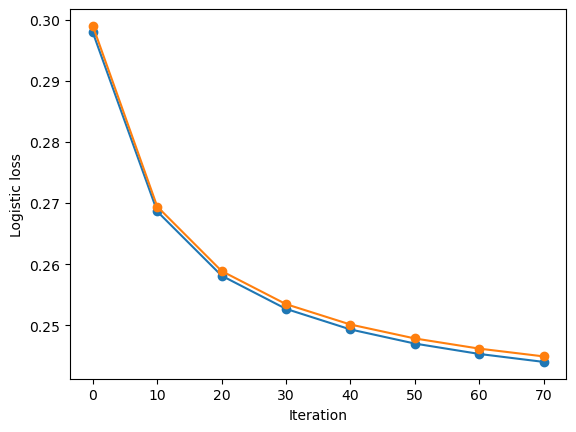

In [ ]:
X_tr=np.array(X_tr,dtype=np.float16)
X_val=np.array(X_val,dtype=np.float16)
X_test=np.array(X_test,dtype=np.float16)
##float16 is a test, may need to up it i used float64 by default but it took 5G of memory for X_tr so impossible to run litterally 

w_ridge, losses,losses_val = lasso_logistic_regression(y_tr,X_tr,np.zeros(X_tr.shape[1]),80,0.1,X_val,y_val,10**-3)

plt.plot(np.arange(len(losses)) * 10, losses, marker="o")
plt.plot(np.arange(len(losses_val)) * 10, losses_val, marker="o")
plt.xlabel("Iteration")
plt.ylabel("Logistic loss")
plt.show()


We absolutely don't care about the performance of this lasso model specifically it is not a model we wish to implement, we just want the mask, meaning lambda will be tuned after that we test the performance of different masks on normal logistic regression. The absolute need of a mask is due to the huge size 

In [11]:
lassomask = np.abs(w_ridge) > 1e-4
lassomask[0] = True  # keep intercept

# feature_names excludes the intercept.
# rmv_feats = np.asarray(feature_names)[~lassomask[1:]]
# print(rmv_feats)

In [12]:
X_tr_selected = X_tr[:, lassomask]
X_val_selected = X_val[:, lassomask]
X_test_selected = X_test[:, lassomask]

In [66]:
del x_train,x_test,X_tr,X_test,X_val

NameError: name 'x_train' is not defined

In [14]:
X_tr_selected.shape

(262508, 417)

In [15]:
def sigmoid(t):
    t = np.clip(t, -500, 500)
    return 1 / (1 + np.exp(-t))

In [16]:
def logistic_regressionstats(y, tx, initial_w, max_iters, gamma,x_val,y_val):
    """Train a logistic regression model using gradient descent.

    Parameters
    ----------
    y : np.ndarray
        Binary target values of shape (n_samples,), usually 0 or 1.
    tx : np.ndarray
        Feature matrix of shape (n_samples, n_features).
    initial_w : np.ndarray
        Initial weight vector of shape (n_features,).
    max_iters : int
        Number of gradient descent iterations.
    gamma : float
        Learning rate used to update the weights.

    Returns
    -------
    w : np.ndarray
        Final learned weight vector of shape (n_features,).
    final_loss : float
        Logistic loss after the final iteration.

    Example
    -------
    y = np.array([0, 1, 1])
    tx = np.array([[0.2, 1.0], [1.0, 0.8], [1.5, 1.2]])
    w0 = np.array([0.0, 0.0])
    w, loss = logistic_regression(y, tx, w0, 200, 0.1)

    Example of use
    --------------
    weights, train_loss = logistic_regression(y_train, tx_train, w_init, 500, 0.01)
    """
    w = initial_w
    losses=[]
    losses_val=[]
    norms=[]
    for i in range(max_iters):
        z = tx @ w
        sigma = np.exp(-np.logaddexp(0, -z))
        gradient = tx.T @ (sigma - y) / len(y)
        w = w - gamma * gradient
        if i%10==0:
            z = tx @ w
            loss = np.sum(np.logaddexp(0, z) - y * z) / len(y)
            losses.append(loss)
            z_val=x_val@w
            val_loss=np.sum(np.logaddexp(0, z_val) - y_val * z_val) / len(y_val)
            losses_val.append(val_loss)
            norms.append(np.linalg.norm(gradient))
    return (w, losses,losses_val,norms)

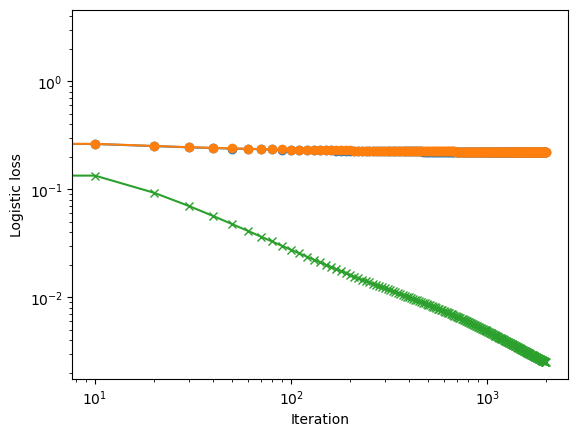

In [73]:
w_logreg, losses,losses_val,norms = logistic_regressionstats(
    y_tr,
    X_tr_selected,
    np.zeros(X_tr_selected.shape[1]),
    2000,
    0.1,X_val_selected,y_val
)

# # w, losses,losses_val = logistic_regressionsium(
# #     y_tr,
# #     X_tr_selected,
# #     w,
# #     600,
# #     0.05,X_val_selected,y_val
# # )



plt.plot(np.arange(len(losses)) * 10, losses, marker="o")
plt.plot(np.arange(len(losses_val)) * 10, losses_val, marker="o")
plt.plot(np.arange(len(losses_val)) * 10, norms, marker="x")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("Logistic loss")
plt.show()



In [74]:
def find_best_tresh(w):
    probabilities = sigmoid(X_val_selected @ w)
    best_f1, best_threshold,acc = -1, 0,0
    total_lenght=len(y_val)
    for threshold in np.linspace(0, 1, 1001):
        pred = probabilities >= threshold

        tp = np.sum(pred & (y_val == 1))
        fp = np.sum(pred & (y_val == 0))
        fn = np.sum(~pred & (y_val == 1))

        denominator = 2 * tp + fp + fn
        f1 = 2 * tp / denominator if denominator else 0.0

        if f1 > best_f1:
            best_f1, best_threshold = f1, threshold
            acc=np.mean(pred==y_val)

    return best_threshold, best_f1,acc

best_treshold_logreg,bestf1,acc=find_best_tresh(w_logreg)
print(bestf1)

##BENEFITS FROM MORE TRAIN

0.43182706081521033


In [82]:
####RETRAINING ON WHOLE DATASET
full=np.concatenate([X_tr_selected,X_val_selected])
y_full = np.concatenate([y_tr, y_val])
wfinal,final_loss=logistic_regression(y_full,full,np.zeros(full.shape[1]),5000,0.1)


In [ ]:
##build submission

probs_sub=sigmoid(X_test_selected@wfinal)
pred_sub=np.where(probs_sub>=best_treshold_logreg,1,-1)
idx = np.loadtxt("dataset/x_stest.csv", delimiter=",", skiprows=1, usecols=0)
create_csv_submission(idx,pred_sub,"submission_logreg.csv")

np.mean(pred_sub==1)


0.14443357500068568

### PART2: WEIGHTED

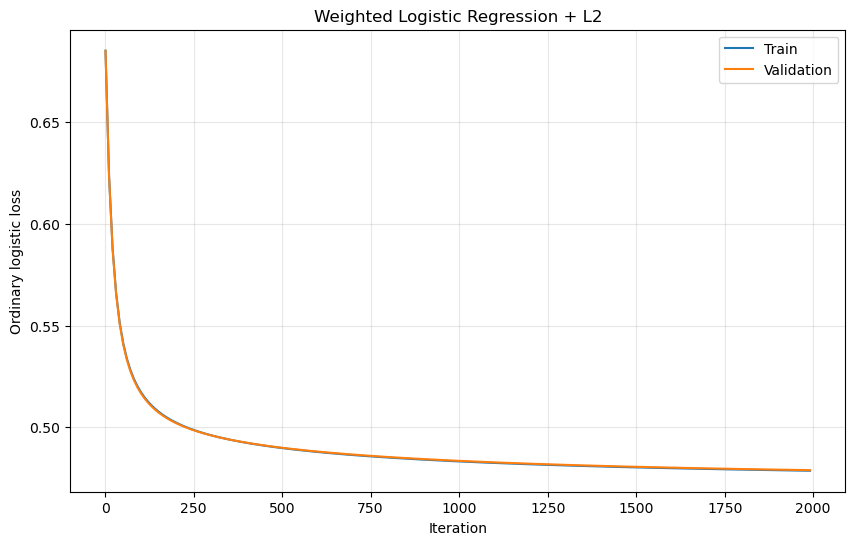

In [20]:
def weighted_logreg_stats(y_tr, y_val, X_tr_selected, X_val_selected,max_iters=2000, gamma=0.01, lambda_=0.01):
    n = len(y_tr)

    pos_weight = n / np.sum(y_tr)
    neg_weight = n / (n - np.sum(y_tr))
    weights = np.where(y_tr == 1, pos_weight, neg_weight)

    w = np.zeros(X_tr_selected.shape[1])

    losses_tr = []
    losses_val = []

    for i in range(max_iters):

        # Forward
        z = X_tr_selected @ w
        sigma = np.exp(-np.logaddexp(0, -z))

        # Weighted gradient + L2
        gradient = X_tr_selected.T @ (weights * (sigma - y_tr)) / n
        gradient += 2 * lambda_ * w

        # Gradient descent
        w -= gamma * gradient

        if i % 10 == 0:
            z = X_tr_selected @ w
            z_val = X_val_selected @ w
            loss_tr = np.mean(np.logaddexp(0, z) - y_tr * z)
            loss_val = np.mean(np.logaddexp(0, z_val) - y_val * z_val)
            losses_tr.append(loss_tr)
            losses_val.append(loss_val)

    return w, losses_tr, losses_val


w_weighted, losses_tr_weighted, losses_val_weighted = weighted_logreg_stats(y_tr, y_val, X_tr_selected, X_val_selected)

iterations = 1 + np.arange(len(losses_tr_weighted)) * 10

plt.figure(figsize=(10, 6))
plt.plot(iterations, losses_tr_weighted, label="Train")
plt.plot(iterations, losses_val_weighted, label="Validation")

plt.xlabel("Iteration")
plt.ylabel("Ordinary logistic loss")
plt.title("Weighted Logistic Regression + L2")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [21]:
def find_best_tresh(w):
    probabilities = sigmoid(X_val_selected @ w)
    best_f1, best_threshold,acc = -1, 0,0
    total_lenght=len(y_val)
    for threshold in np.linspace(0, 1, 1001):
        pred = probabilities >= threshold

        tp = np.sum(pred & (y_val == 1))
        fp = np.sum(pred & (y_val == 0))
        fn = np.sum(~pred & (y_val == 1))

        denominator = 2 * tp + fp + fn
        f1 = 2 * tp / denominator if denominator else 0.0

        if f1 > best_f1:
            best_f1, best_threshold = f1, threshold
            acc=np.mean(pred==y_val)

    return best_threshold, best_f1,acc

best_treshold,bestf1,acc=find_best_tresh(w_weighted)
print(bestf1)

0.42370095061110713


## PART 3 Linear SVM

In [22]:
def calculate_coordinate_update(y, X, lambda_, alpha, w, n):
    """compute a coordinate update (closed form) for coordinate n.

    Args:
        y: the corresponding +1 or -1 labels, shape = (num_examples)
        X: the dataset matrix, shape = (num_examples, num_features)
        lambda_: positive scalar number
        alpha: vector of dual coordinates, shape = (num_examples)
        w: vector of primal parameters, shape = (num_features)
        n: the coordinate to be updated

    Returns:
        w: updated vector of primal parameters, shape = (num_features)
        alpha: updated vector of dual parameters, shape = (num_examples)

    >>> y_test = np.array([1, -1])
    >>> x_test = np.array([[1., 2., 3.], [4., 5., 6.]])
    >>> w_test = np.array([-0.3, -0.3, -0.3])
    >>> alpha_test = np.array([0.1, 0.1])
    >>> calculate_coordinate_update(y_test, x_test, 1, alpha_test, w_test, 0)
    (array([-0.1,  0.1,  0.3]), array([0.5, 0.1]))
    """
    # calculate the update of coordinate at index=n.
    N = y.size
    x_n, y_n = X[n], y[n]
    old_alpha_n = np.copy(alpha[n])
    multQn=y_n*x_n.T@w
    Qnn=np.linalg.norm(x_n)**2
    extra=np.clip(lambda_*N*(1-multQn)/Qnn,-old_alpha_n,1-old_alpha_n)
    alpha[n] += extra
    w += extra * y_n * x_n / (lambda_ * N)

    return w, alpha

In [23]:
def calculate_primal_objective(y, X, w, lambda_):
    """compute the full cost (the primal objective, equation (1) in the exercise pdf),
        that is loss plus regularizer.

    Args:
        X: the full dataset matrix, shape = (num_examples, num_features)
        y: the corresponding +1 or -1 labels, shape = (num_examples)
        w: shape = (num_features)

    Returns:
        scalar, non-negative

    >>> y_test = np.array([1, -1])
    >>> x_test = np.array([[1, 2, 3], [4, 5, 6]])
    >>> w_test = np.array([0, 1, 5])
    >>> calculate_primal_objective(y_test, x_test, w_test, 1)
    31.0
    """
    z=1-y*(X@w)
    loss=np.mean(np.maximum(0,z))+lambda_/2*np.linalg.norm(w)**2
    return loss






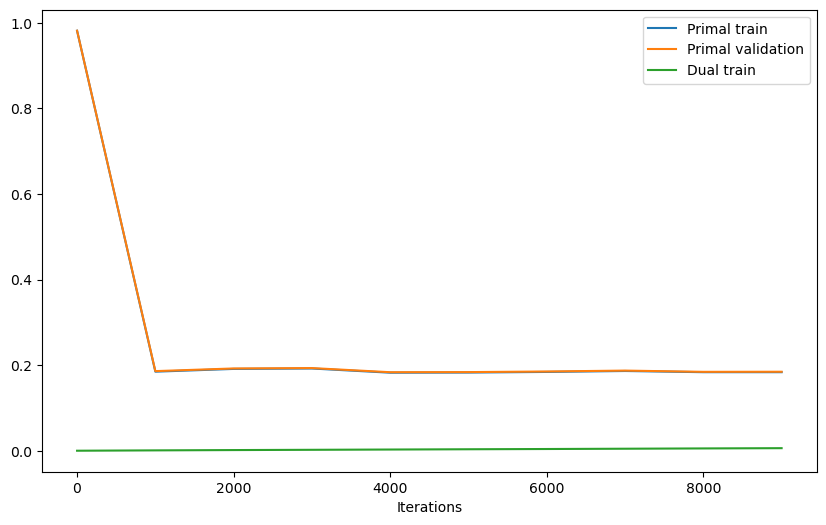

In [ ]:
def coordinate_descent_for_svm_demo(y_tr, X_tr, y_val, X_val):
    max_iter = int(1e4)
    lambda_ = 0.01

    p_costs_tr, d_costs_tr, p_costs_val = [], [], []
    iterations = []

    N, d = X_tr.shape
    w = np.zeros(d)
    alpha = np.zeros(N)

    for it in range(max_iter):
        n = np.random.randint(N)

        w, alpha = calculate_coordinate_update(
            y_tr, X_tr, lambda_, alpha, w, n
        )

        if it % 1000 == 0:
            primal_tr = calculate_primal_objective(y_tr, X_tr, w, lambda_)
            primal_val = calculate_primal_objective(y_val, X_val, w, lambda_)
            dual_tr = np.mean(alpha) - lambda_ / 2 * np.dot(w, w)

            p_costs_tr.append(primal_tr)
            p_costs_val.append(primal_val)
            d_costs_tr.append(dual_tr)
            iterations.append(it + 1)

    plt.figure(figsize=(10, 6))
    plt.plot(iterations, p_costs_tr, label="Primal train")
    plt.plot(iterations, p_costs_val, label="Primal validation")
    plt.plot(iterations,d_costs_tr,label="Dual train")
    plt.xlabel("Iterations")
    plt.legend()
    plt.show()


    return w, alpha


w_svm,alpha=coordinate_descent_for_svm_demo(2*(y_tr-0.5), X_tr_selected,2*(y_val-0.5),X_val_selected)

dual cost needs more iterations but primal already converged no need to go further, svm just predicts one class

In [ ]:
def find_best_tresh(w):
    scores= (X_val_selected @ w)
    best_f1, best_threshold,acc = -1, 0,0
    total_lenght=len(y_val)
    for threshold in np.linspace(-100, 100, 1001):
        pred = scores >= threshold

        tp = np.sum(pred & (y_val == 1))
        fp = np.sum(pred & (y_val == 0))
        fn = np.sum(~pred & (y_val == 1))
        
        denominator = 2 * tp + fp + fn
        f1 = 2 * tp / denominator if denominator else 0.0

        if f1 > best_f1:
            best_f1, best_threshold = f1, threshold
            acc=np.mean(pred==y_val)

    return best_threshold, best_f1,acc


y_svm = 2 * y_val - 1
margins = y_svm * (X_val_selected @ w_svm)

scores = X_val_selected @ w_svm

print("Predicted positives:", np.sum(scores >= 0))
print("Predicted negatives:", np.sum(scores < 0))
print("Positive rate:", np.mean(scores >= 0))

best_treshold,bestf1,acc=find_best_tresh(w_svm)
print(bestf1,best_treshold)

Predicted positives: 4
Predicted negatives: 65623
Positive rate: 6.09505234126198e-05
0.35834098305933404 -1.0


In [69]:
sorted(
    [(name, f"{obj.nbytes / 1024**3:.3f} GiB", obj.shape, str(obj.dtype))
     for name, obj in list(globals().items())
     if isinstance(obj, np.ndarray)],
    key=lambda item: globals()[item[0]].nbytes,
    reverse=True
)

[('X_tr_selected', '0.816 GiB', (262508, 417), 'float64'),
 ('X_test_selected', '0.340 GiB', (109379, 417), 'float64'),
 ('X_val_selected', '0.204 GiB', (65627, 417), 'float64'),
 ('corr', '0.053 GiB', (2659, 2659), 'float64'),
 ('i', '0.026 GiB', (3533811,), 'int64'),
 ('j', '0.026 GiB', (3533811,), 'int64'),
 ('mask', '0.003 GiB', (3533811,), 'bool'),
 ('y_train', '0.002 GiB', (328135,), 'int64'),
 ('train_ids', '0.002 GiB', (328135,), 'int64'),
 ('y', '0.002 GiB', (328135,), 'float64'),
 ('indices', '0.002 GiB', (328135,), 'int64'),
 ('tr', '0.002 GiB', (262508,), 'int64'),
 ('y_tr', '0.002 GiB', (262508,), 'float64'),
 ('alpha', '0.002 GiB', (262508,), 'float64'),
 ('test_ids', '0.001 GiB', (109379,), 'int64'),
 ('val', '0.000 GiB', (65627,), 'int64'),
 ('y_val', '0.000 GiB', (65627,), 'float64'),
 ('y_svm', '0.000 GiB', (65627,), 'float64'),
 ('margins', '0.000 GiB', (65627,), 'float64'),
 ('scores', '0.000 GiB', (65627,), 'float64'),
 ('w_ridge', '0.000 GiB', (2659,), 'float64'),